# Modeling single-cell proximity data from chromatin tracing experiments

#### A tutorial in using the `topic3d` software package for model training and data decomposition 

## Background

In this tutorial, we will
- load some in pairwise proximity data and visualize it
- train an LDA model on this data and evaluate the model's quality
- visualize the results of the modeling

Importing required modules

In [1]:
from os import path
import numpy as np
from topic3d.datatypes import PWProxArrayStack
from IPython.display import Image

### Visualizing the sample data

In [2]:
data = PWProxArrayStack(np.load("./data/sample_exp.npy"))
data.shape

(1745, 946)

Plotting random examples from this ensemble shows us the diversity in individual (read, "single-cell") maps. Our goal is to use LDA to decompose this data based on patterns in proximity co-occurrence. Since the red pixels indicate the regions in proximity, LDA simply needs to find patterns in pixel co-occurrence. 

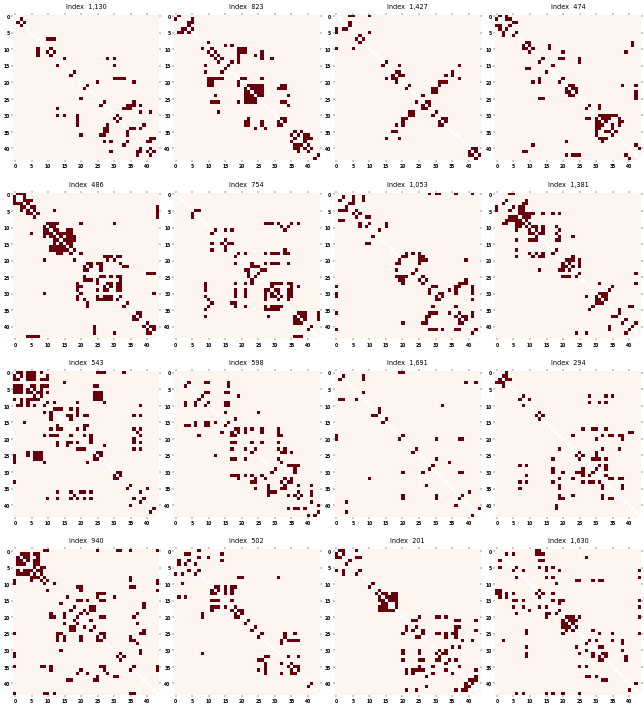

In [3]:
fig = data.plot_random_examples(num_items=16,
                                random_seed=None,
                                form="square",
                                include_cbar=False)
fig.set_dpi(36)
fig.show()

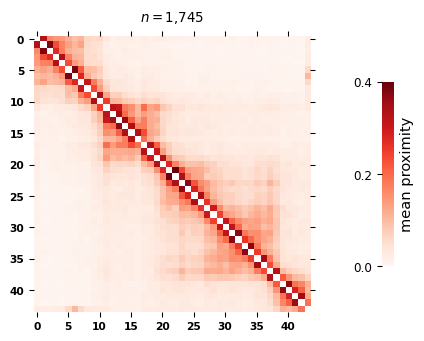

In [4]:
fig = data.plot_ensemble_measure(method="mean", form="square", cbar_label="mean proximity")
fig.set_dpi(96)
fig.show()

### Model training and dataset decomposition

In [5]:
dir_results = "./results/bintu_example"

In [6]:
!topic3d runall \
    --data_train_file "./data/sample_exp.npy" \
    --results_dir "./results/bintu_example" \
    --num_CFMs 15 \
    --max_iter 100 \
    --evaluate_learning

2026-03-19 17:10:24,218 [INFO] --------------------------------------------------
2026-03-19 17:10:24,218 [INFO] [58b8f9] Will save run outputs to: ./results/bintu_example
2026-03-19 17:10:24,219 [INFO] Settings summary for run: 58b8f9
2026-03-19 17:10:24,219 [INFO]     data_train_file: ./data/sample_exp.npy
2026-03-19 17:10:24,219 [INFO]     data_test_file: None
2026-03-19 17:10:24,219 [INFO]     model_file: None
2026-03-19 17:10:24,219 [INFO]     results_dir: ./results/bintu_example
2026-03-19 17:10:24,219 [INFO]     params_file: None
2026-03-19 17:10:24,219 [INFO]     num_CFMs: 15
2026-03-19 17:10:24,219 [INFO]     max_iter: 100
2026-03-19 17:10:24,219 [INFO]     random_state: None
2026-03-19 17:10:24,220 [INFO]     learning_method: batch
2026-03-19 17:10:24,220 [INFO]     batch_size: 128
2026-03-19 17:10:24,220 [INFO]     evaluate_learning: True
2026-03-19 17:10:24,220 [INFO]     assess_model_quality: False
2026-03-19 17:10:24,220 [INFO]     uid: 58b8f9
2026-03-19 17:10:24,220 [INF

Since we passed the `evaluate_learning` parameter, we can verify the plateau reached in the perplexity during training.

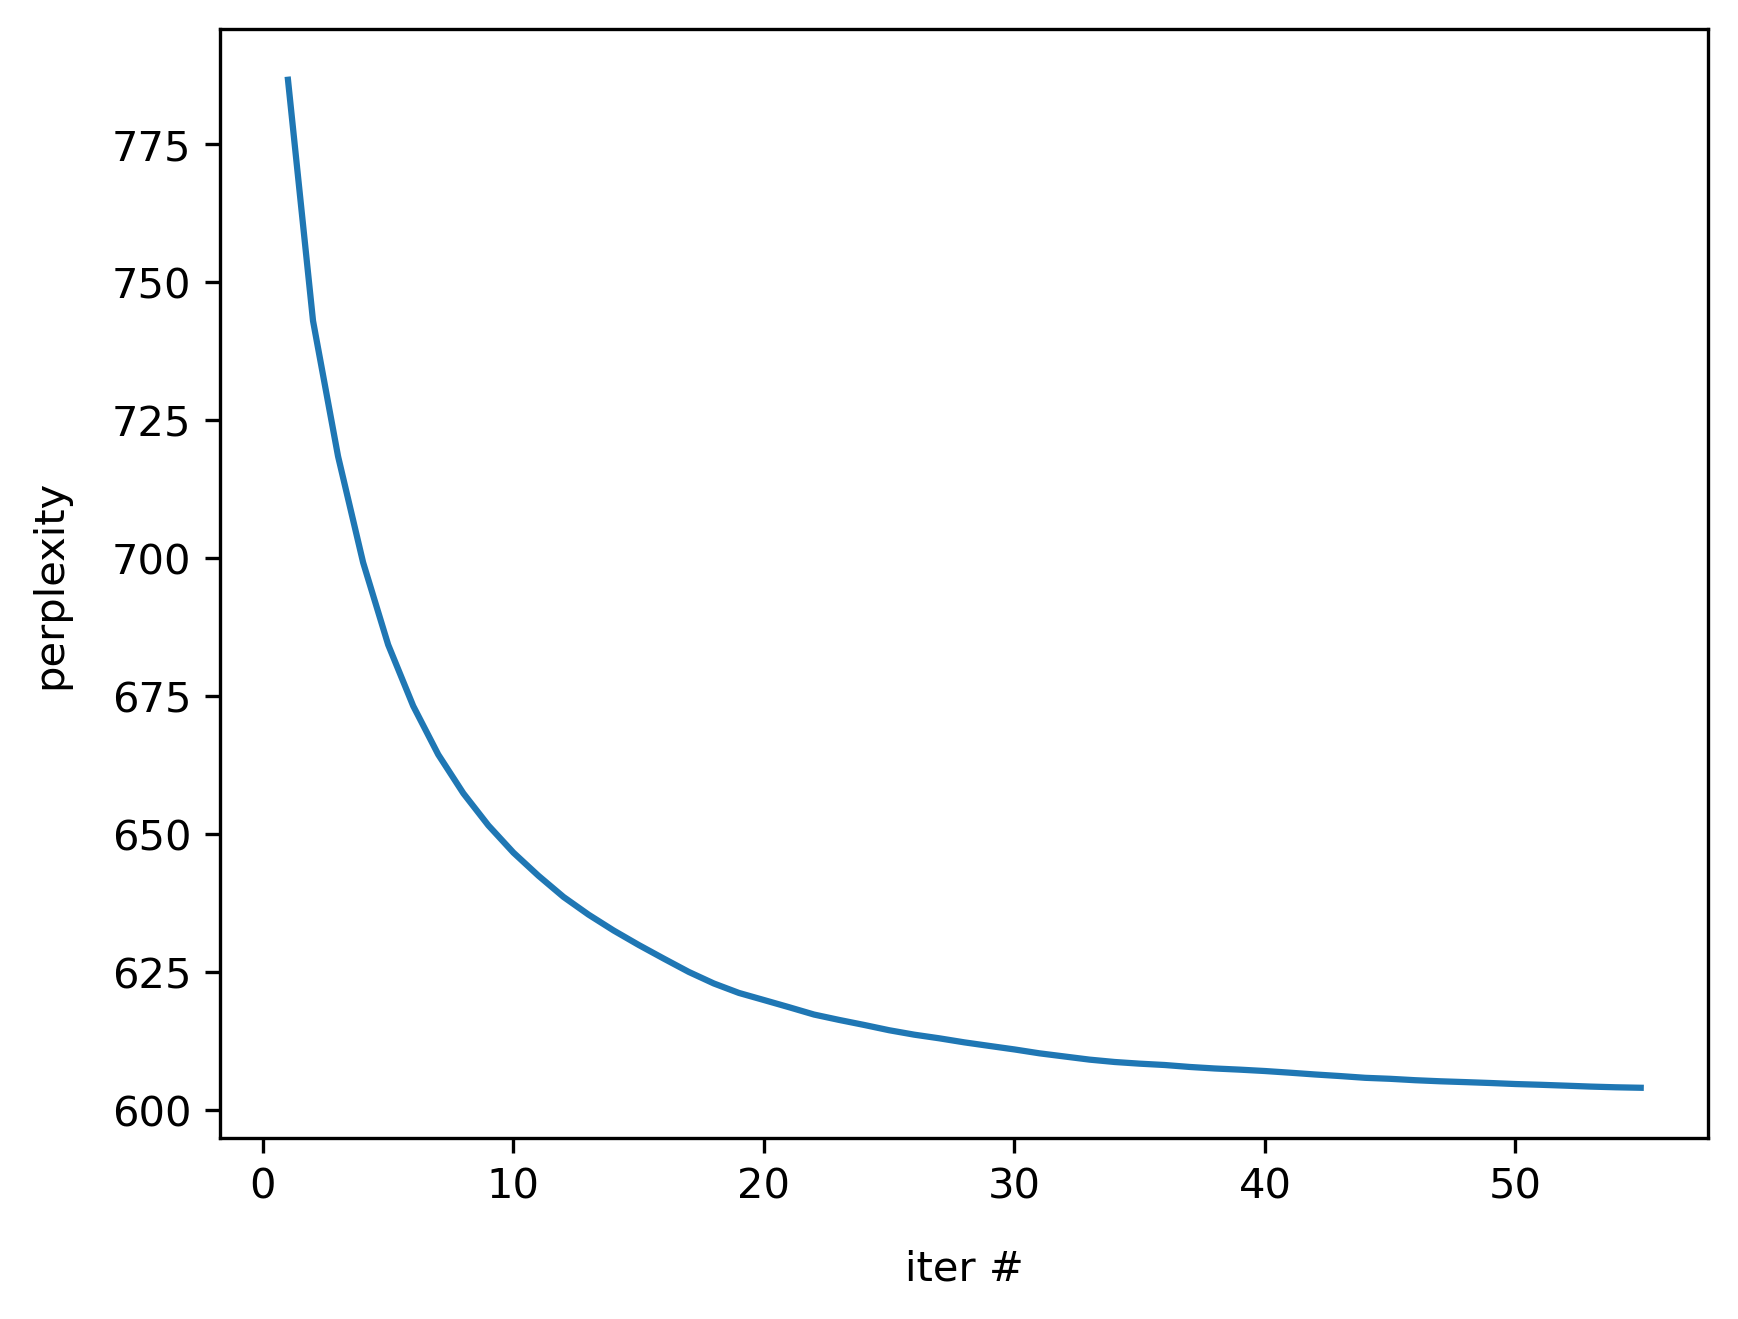

In [7]:
Image(filename=path.join(dir_results, "perplexity_evolution.png"), width=500, height=400)

## Visualizing the results

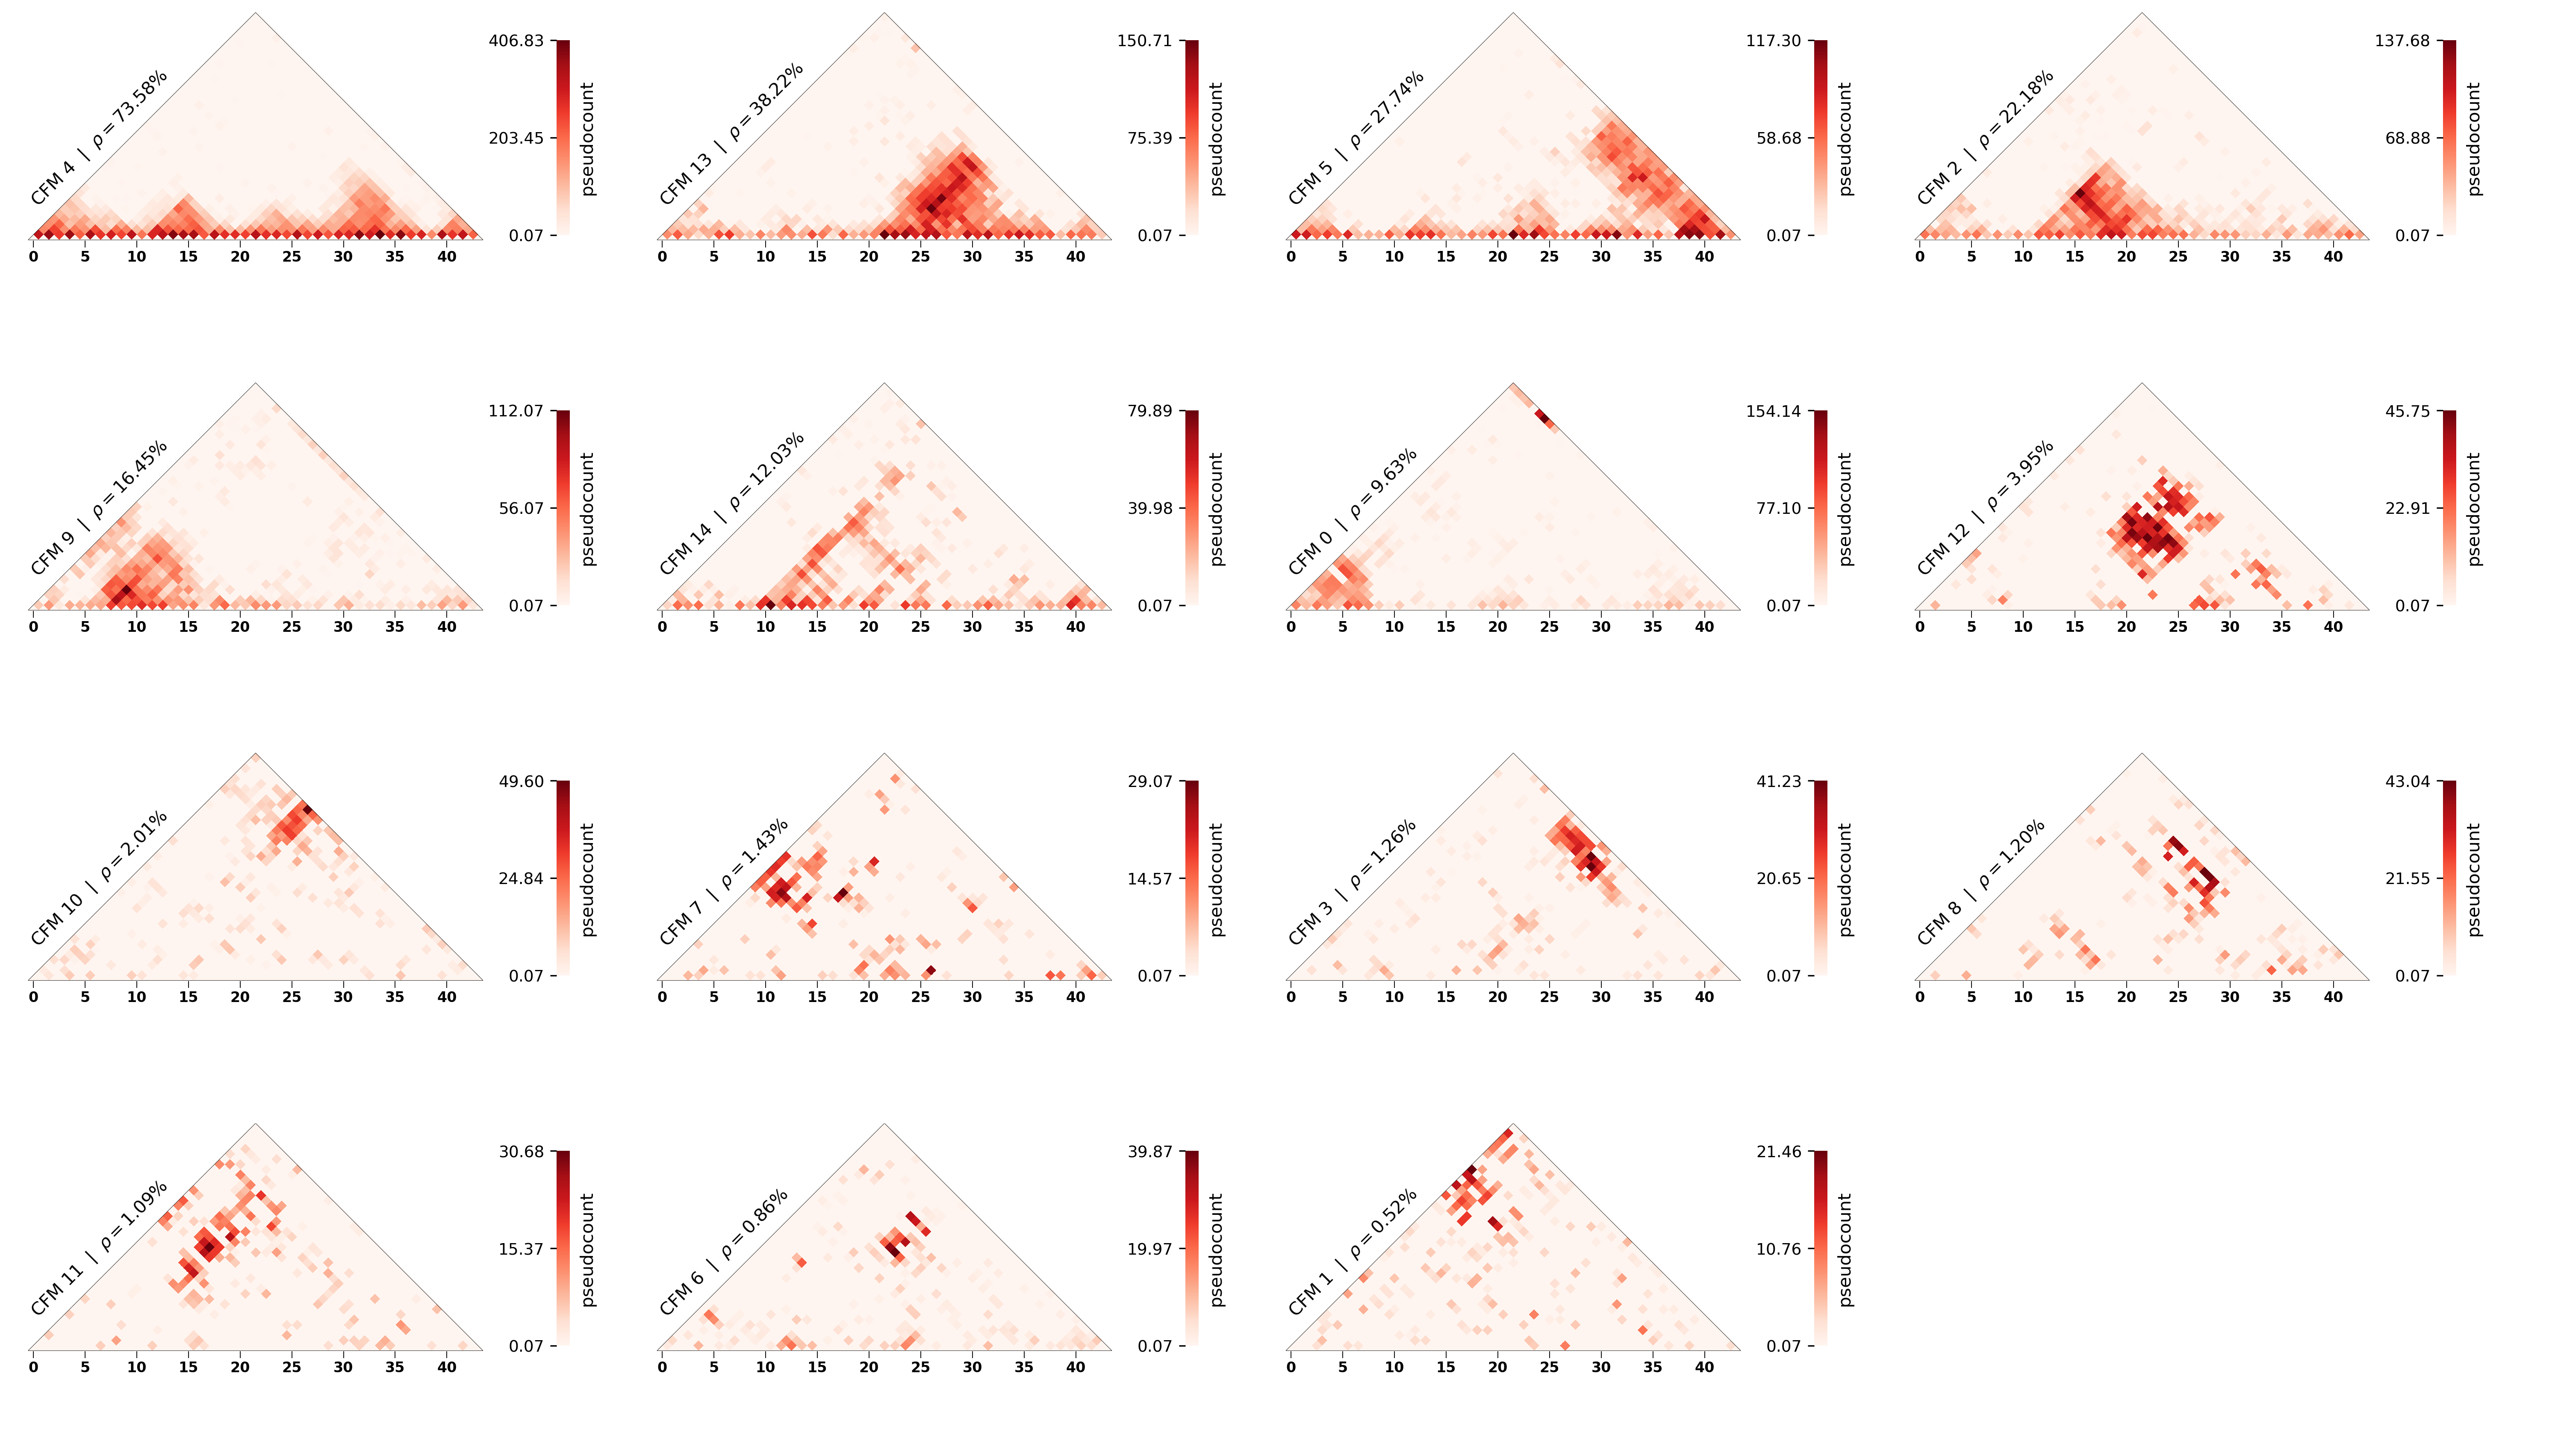

In [8]:
Image(filename=path.join(dir_results, "CFMs_ordered.png"))

The decomposition matrix shows the probability of assignment of each single trace to each CFM. A high probability indicates that the CFM is present in that trace.

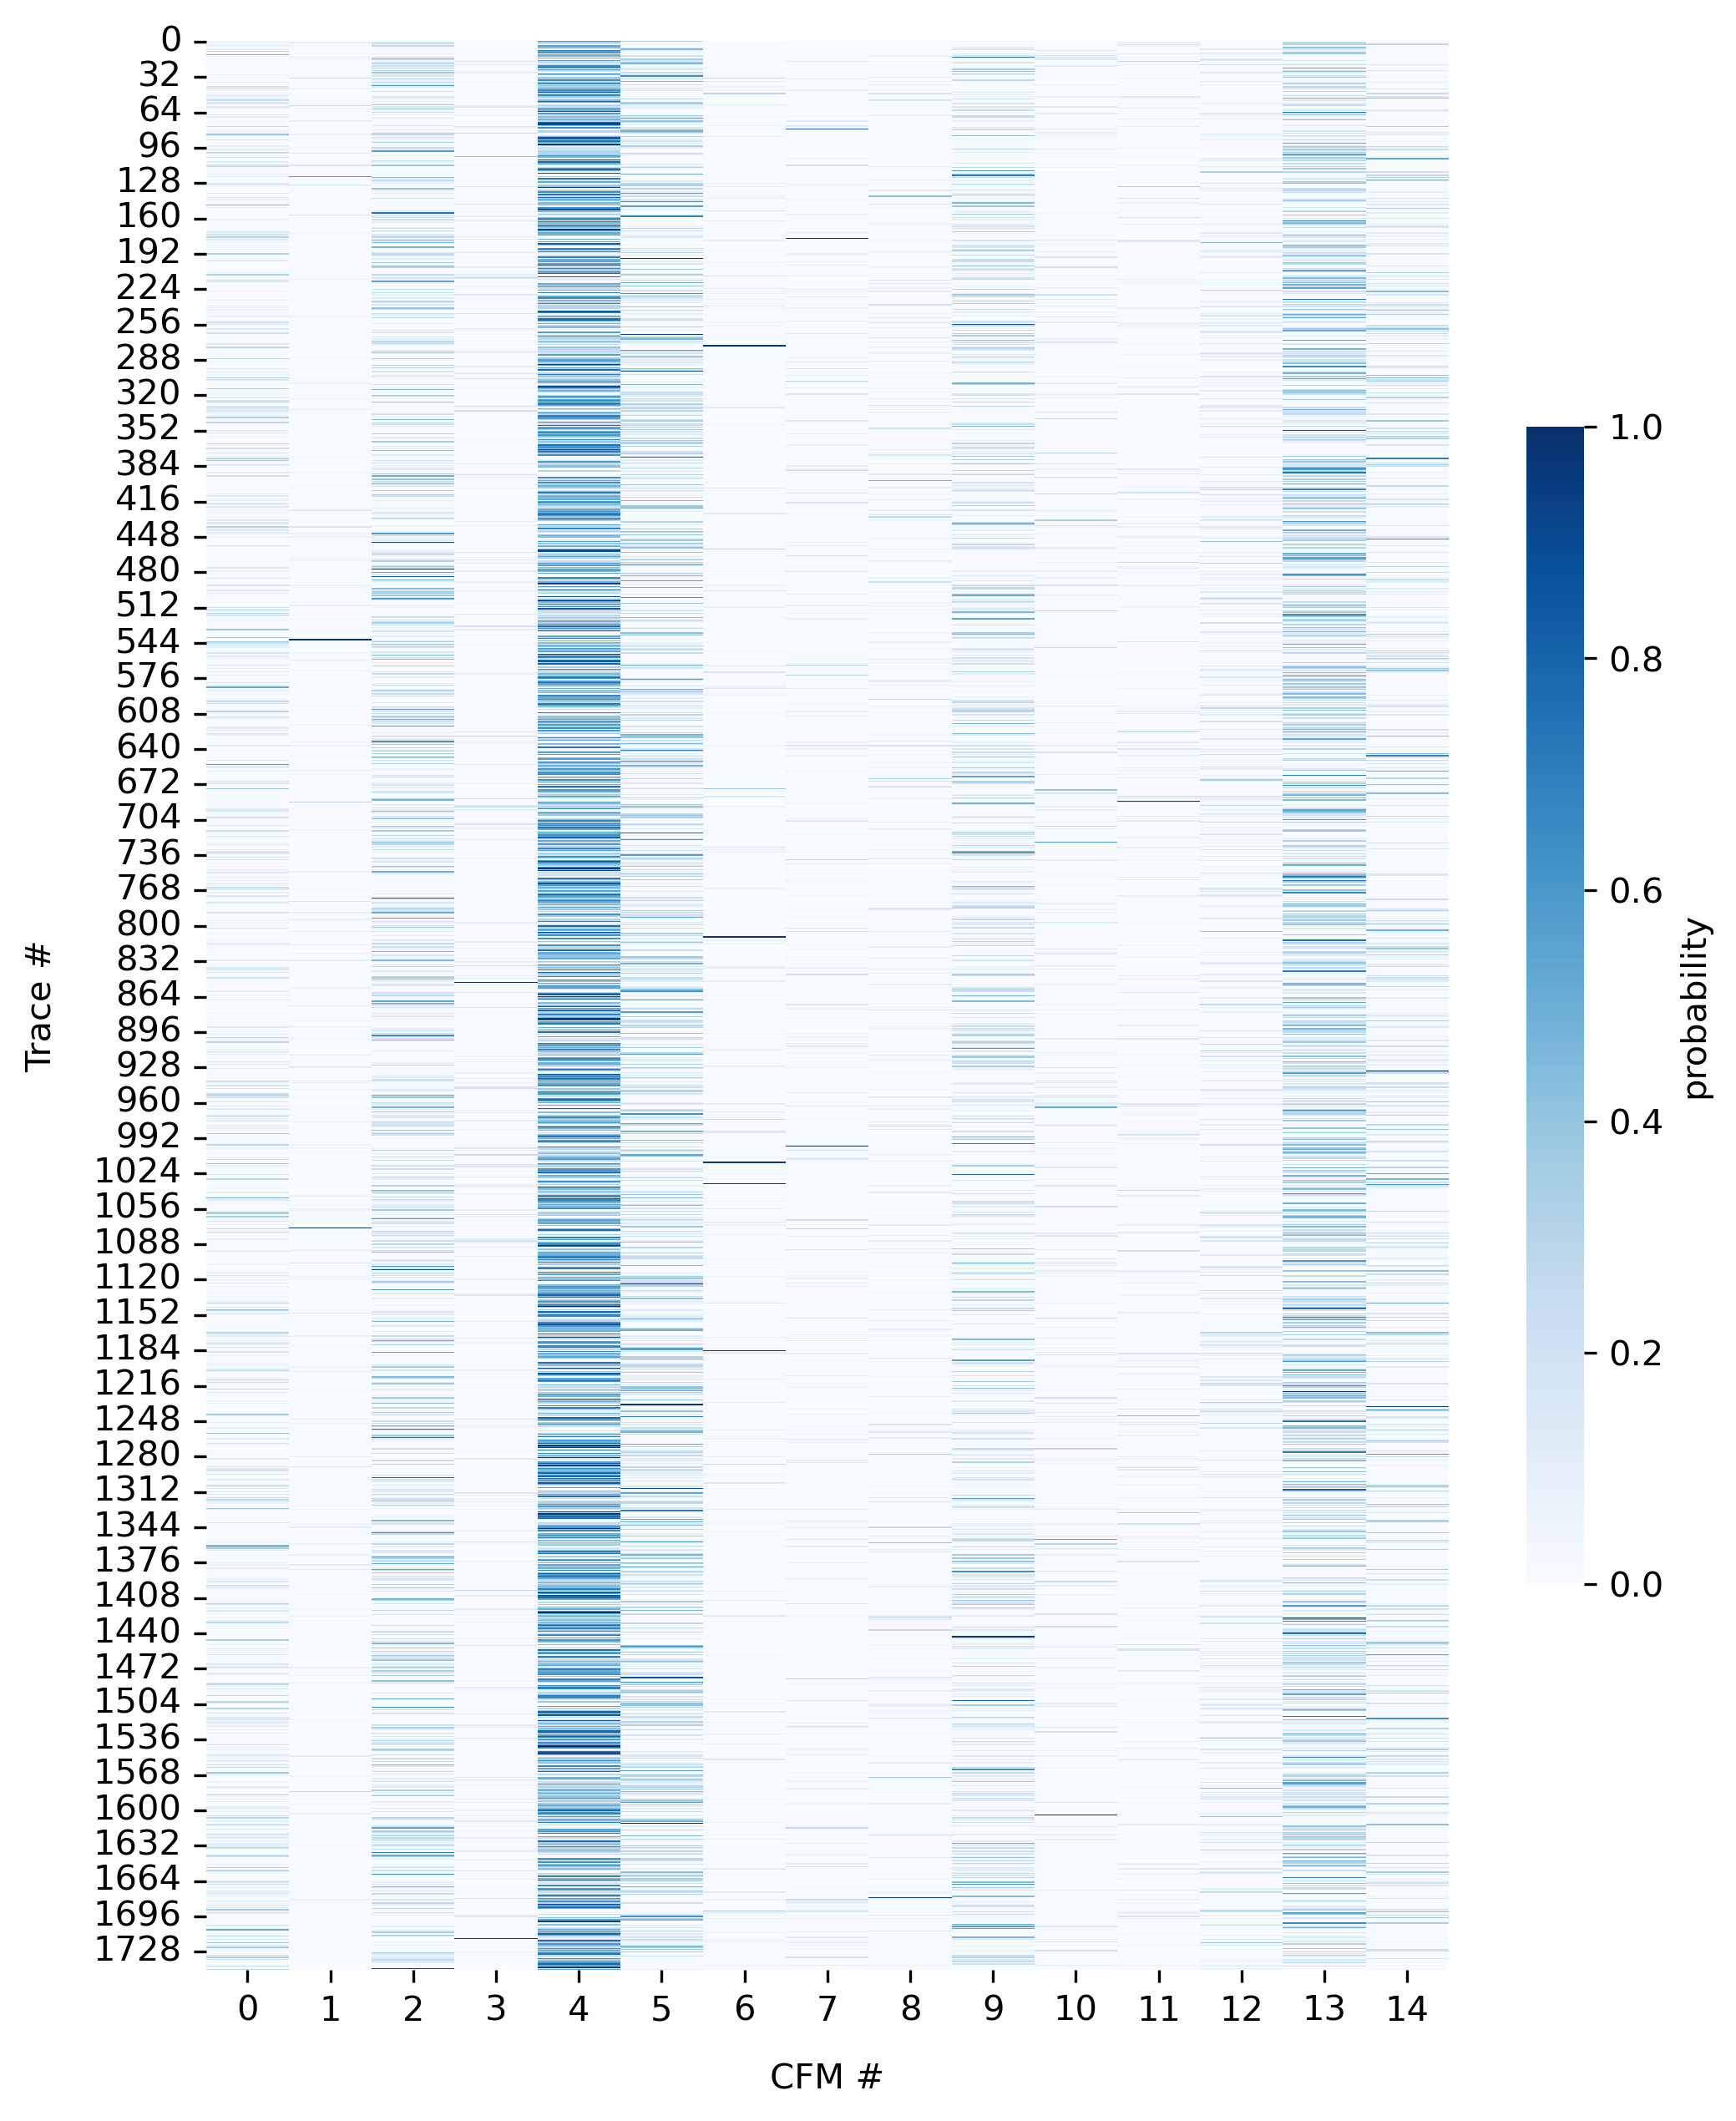

In [9]:
Image(filename=path.join(dir_results, "decomposition.png"), width=600, height=1000)

Ordering the decomposition matrix by most frequently occurring CFM (along the x-axis) and the most representative single traces for each CFM (y-axis) gives us a better understanding of CFM usage in different cells. 

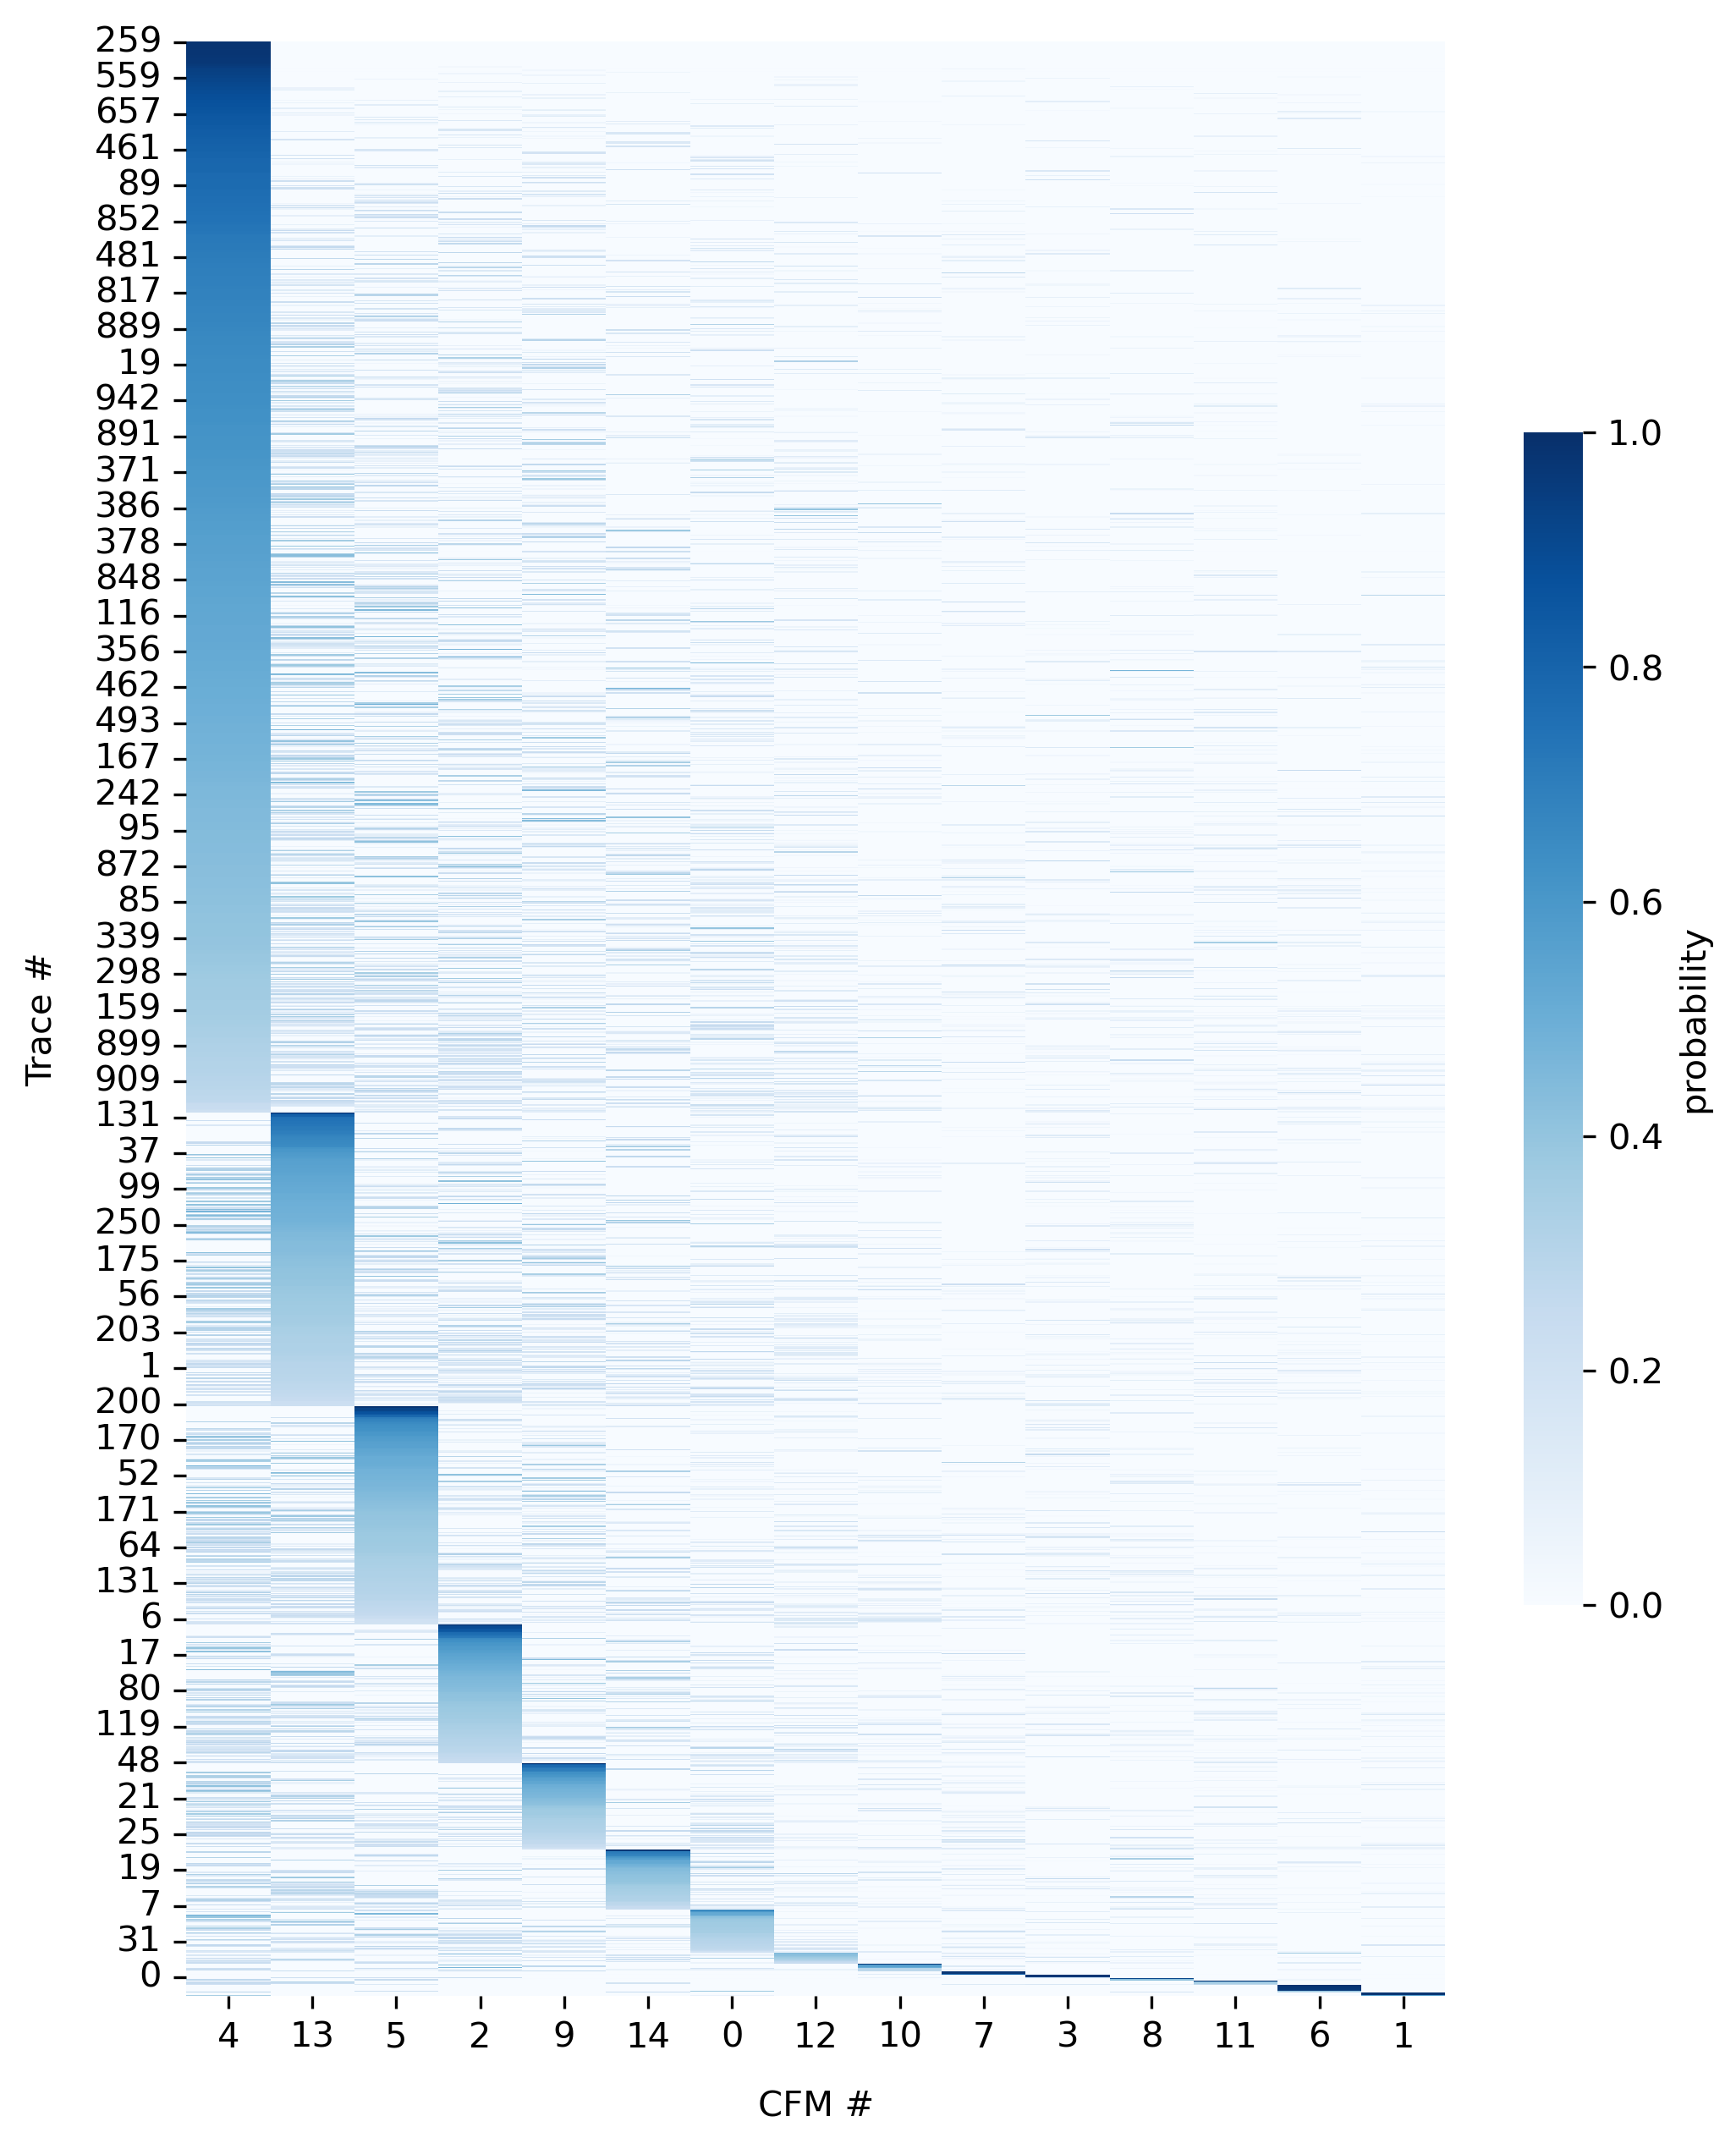

In [10]:
Image(filename=path.join(dir_results, "decomposition_ordered.png"), width=600, height=1000)

Analysis of this matrix is useful for interpretation of the data. For example, one can cluster single traces hierarchically to find groups with similar CFM usage.